---
title: "Practice Activity 11-2: Classification Models"
author: "Shiqi Wu"
format:
  html:
    embed-resources: true
    html-math-method: mathml
    code-overflow: wrap
---

# Classification Models

## Discussion questions

Suppose you are developing a classification model to determine whether or not a person has a particular disease (based on symptoms, results of diagnostic tests, family history, risk factors, etc).

1. Explain what "precision" represents in this context.

**Answer:** Precision is the proportion of people predicted to have the disease who actually have it. A higher precision means fewer false positives among the people predicted to have the disease.

**Discuss with your partner, and make notes here.**

2. Explain what "recall" represents in this context.

**Answer:** Recall is the proportion of people who actually have the disease who are correctly identified by the model. A higher recall means fewer people with the disease are missed.

**Discuss with your partner, and make notes here.**

3. Which of the following do you think is a more serious error? It's an opinion question, but choose one and discuss.

- Concluding that a person has the disease if they actually don't have it
- Failing to conclude that a person has the disease if they actually do have it

**Answer:** I think failing to identify a person who actually has the disease is more serious. The person may not receive the testing or treatment they need, and their condition could become worse because of the delay.

**Discuss with your partner, and make notes here.**

4. Given your answer to the previous question, which would you prefer to be higher: precision or recall?

**Answer:** I would prefer higher recall because I think missing a person who actually has the disease is the more serious error. Higher recall means the model identifies a larger proportion of people with the disease and misses fewer of them.

**Discuss with your partner, and make notes here.**

5. Suppose you want to achieve higher recall. Should your classification rule be more or less strict about who it predicts to have the disease?

**Answer:** The classification rule should be less strict about predicting that a person has the disease. Lowering the probability threshold allows more people to be classified as positive, which can help identify more people who actually have the disease and increase recall.

**Discuss with your partner, and make notes here.**

6. What is a downside to your choice in the previous part?

**Answer:** A less strict rule may produce more false positives, meaning more people without the disease are predicted to have it. This can lower precision and lead to unnecessary follow-up tests, extra costs, and anxiety.

**Discuss with your partner, and make notes here.**

In [1]:
import pandas as pd
import numpy as np

## More wine

The wines data set (https://dlsun.github.io/pods/data/wines.csv ) contains data about the chemical composition of various wines. We'll first use just two features&mdash;fixed acidity and volatile acidity&mdash;to predict the color of the wine (red or white).

In [2]:
df_train = pd.read_csv("https://dlsun.github.io/pods/data/wines.csv")

df_train

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white


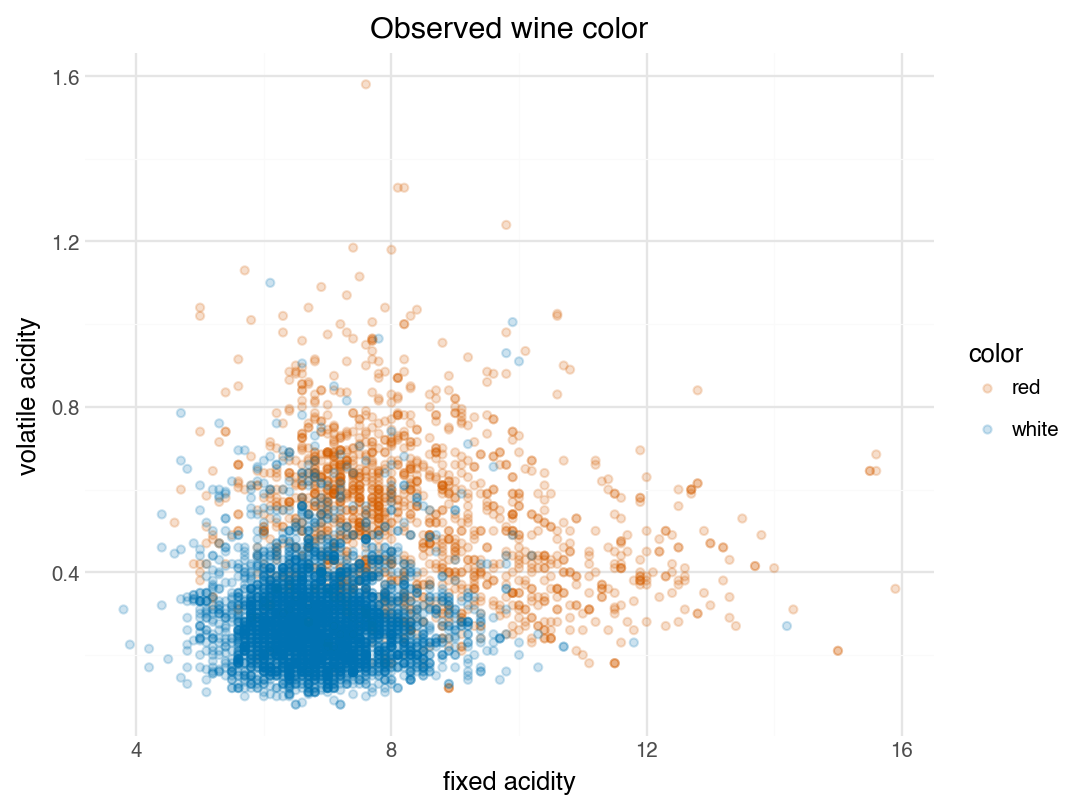

In [3]:
from plotnine import *

(
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Observed wine color")
    + theme_minimal()
)

1\. Fit a 15-nearest neighbors model for predicting color from fixed acidity and volatile acidity. Don't forget to scale the features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the observed colors.

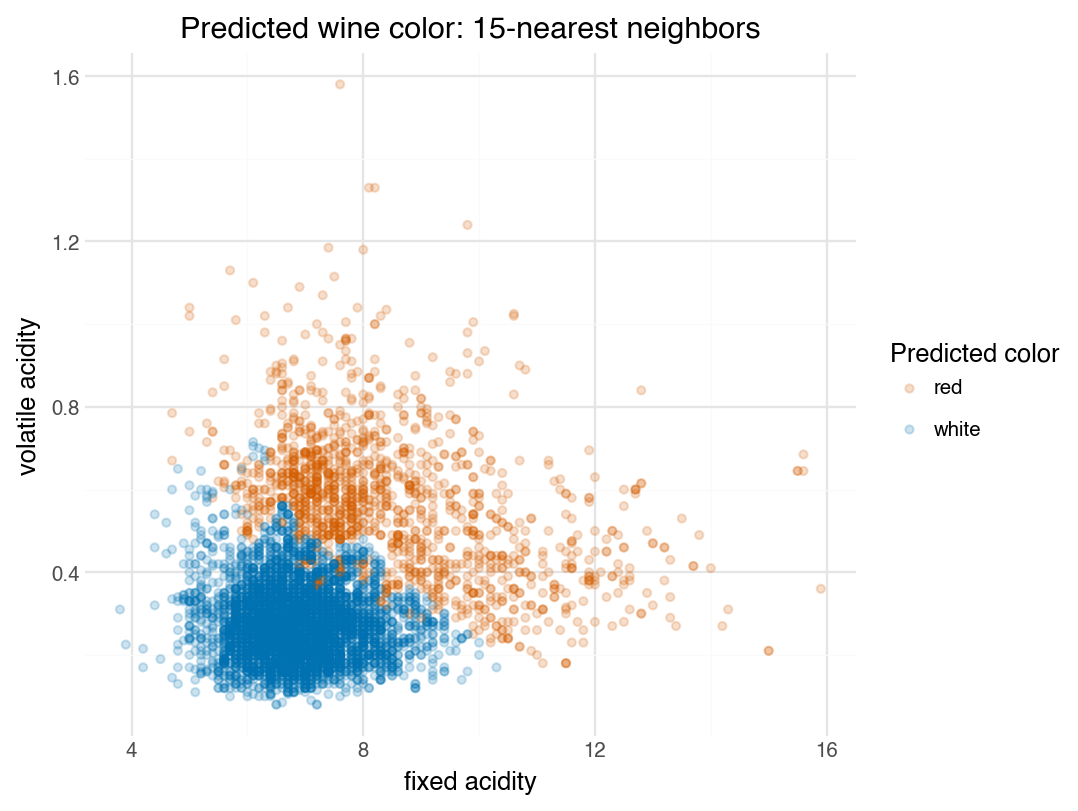

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

X_train = df_train[["fixed acidity", "volatile acidity"]]
y_train = df_train["color"]

knn_pipeline = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15)
)

knn_pipeline.fit(X_train, y_train)

df_knn_predictions = df_train.assign(
    predicted_color=knn_pipeline.predict(X_train)
)

(
    ggplot(
        df_knn_predictions,
        aes(
            x="fixed acidity",
            y="volatile acidity",
            color="predicted_color"
        )
    )
    + geom_point(alpha=0.2)
    + scale_color_manual(
        values={"red": "#D55E00", "white": "#0072B2"}
    )
    + labs(
        title="Predicted wine color: 15-nearest neighbors",
        color="Predicted color"
    )
    + theme_minimal()
)

**Answer:** The predicted colors show a similar overall pattern to the observed colors. White wines are mostly found at lower fixed acidity and lower volatile acidity, while red wines tend to have higher values of one or both features. The predicted plot shows a clearer separation between the two colors, but some wines in the overlapping areas are classified incorrectly.

2\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score using `macro` scoring.

In [5]:
from sklearn.model_selection import cross_validate

knn_cv_results = cross_validate(
    knn_pipeline,
    X_train,
    y_train,
    cv=10,
    scoring={
        "precision": "precision_macro",
        "recall": "recall_macro",
        "f1": "f1_macro"
    }
)

knn_cv_scores = pd.DataFrame({
    "Metric": ["Precision (macro)", "Recall (macro)", "F1 (macro)"],
    "Mean CV score": [
        knn_cv_results["test_precision"].mean(),
        knn_cv_results["test_recall"].mean(),
        knn_cv_results["test_f1"].mean()
    ]
})

knn_cv_scores

,Metric,Mean CV score
0,Precision (macro),0.881381
1,Recall (macro),0.854369
2,F1 (macro),0.863297


3\. Use `GridSearchCV` to fit $k$-nearest neighbors models for $k=1,\ldots, 30$ and use cross validation to estimate the test F1 macro score. Plot the test score versus $k$. Which value of $k$ yields the best score?

Best k: 16
Best mean CV F1 (macro): 0.866427


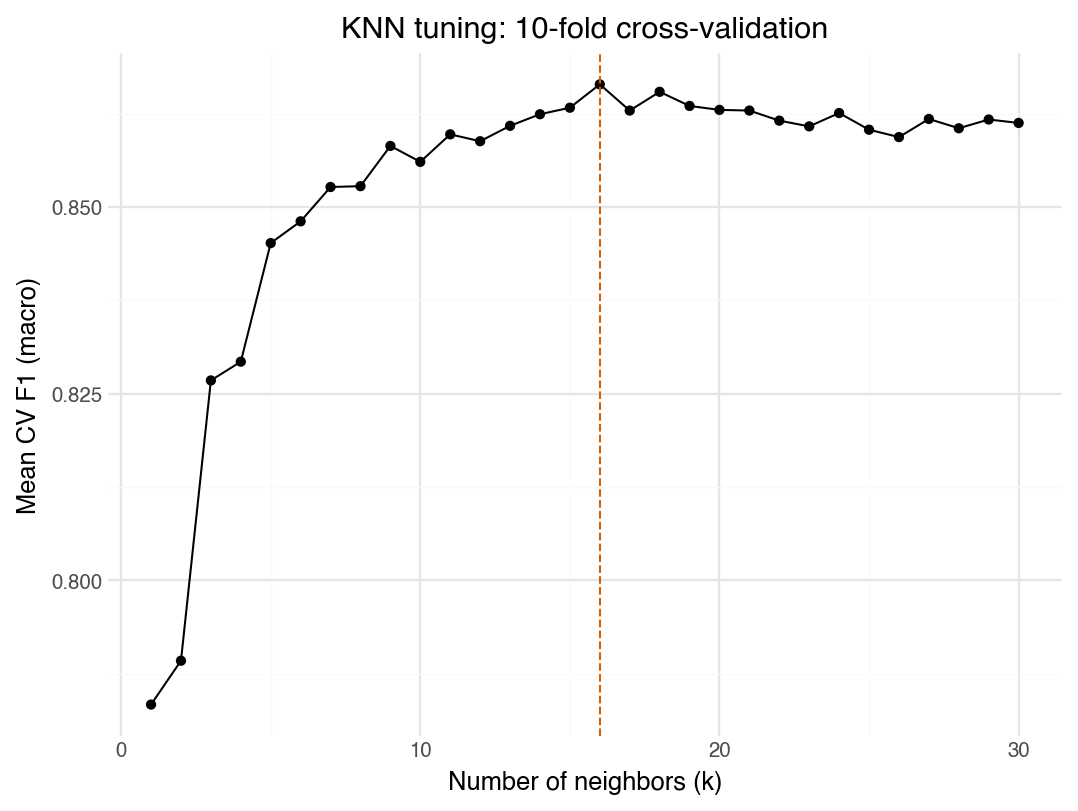

In [7]:
from sklearn.model_selection import GridSearchCV

knn_grid_search = GridSearchCV(
    knn_pipeline,
    param_grid={
        "kneighborsclassifier__n_neighbors": range(1, 31)
    },
    scoring="f1_macro",
    cv=10
)

knn_grid_search.fit(X_train, y_train)

knn_tuning_results = pd.DataFrame({
    "k": knn_grid_search.cv_results_[
        "param_kneighborsclassifier__n_neighbors"
    ].astype(int),
    "Mean CV F1 (macro)": knn_grid_search.cv_results_[
        "mean_test_score"
    ]
}).sort_values("k")

best_k = knn_grid_search.best_params_[
    "kneighborsclassifier__n_neighbors"
]

print(f"Best k: {best_k}")
print(f"Best mean CV F1 (macro): {knn_grid_search.best_score_:.6f}")

(
    ggplot(
        knn_tuning_results,
        aes(x="k", y="Mean CV F1 (macro)")
    )
    + geom_line()
    + geom_point()
    + geom_vline(
        xintercept=best_k,
        linetype="dashed",
        color="#D55E00"
    )
    + labs(
        title="KNN tuning: 10-fold cross-validation",
        x="Number of neighbors (k)",
        y="Mean CV F1 (macro)"
    )
    + theme_minimal()
)

**Answer:** Among the values from 1 to 30, k = 16 gives the highest mean F1 macro score of about 0.8664 using 10-fold cross-validation. The score generally increases as k rises from 1 to 16, then stays close to the highest score with small fluctuations. Based on these results, I would choose k = 16.

4\. When the target variable is binary **logistic regression** provides another classification algorithm.

Fit a logistic regression model for predicting wine color from the two features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the predictions from the nearest neighbors classifier.

Note: with regression, you don't need to scale the features (unless you add a penalty). Hint: you basically just need to replace with `KNeighborsClassifier()` with `LogisticRegression()`.

/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters


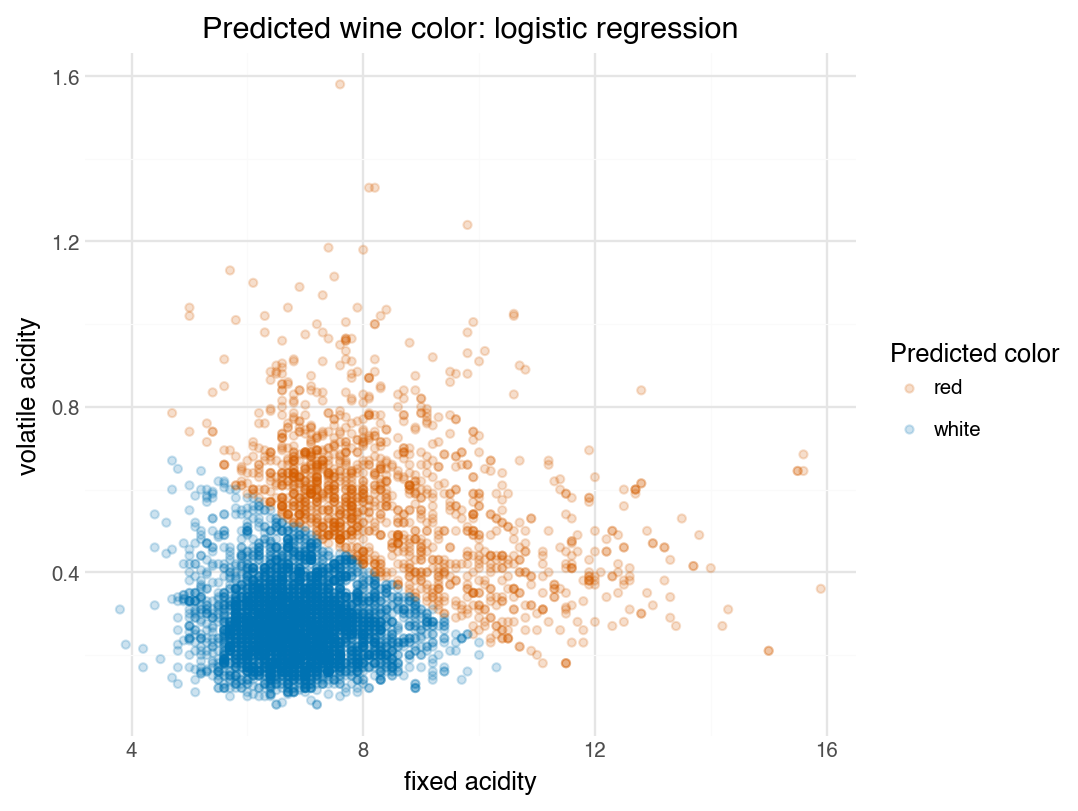

In [9]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    C=np.inf,
    max_iter=1000
)

logistic_model.fit(X_train, y_train)

df_logistic_predictions = df_train.assign(
    predicted_color=logistic_model.predict(X_train)
)

(
    ggplot(
        df_logistic_predictions,
        aes(
            x="fixed acidity",
            y="volatile acidity",
            color="predicted_color"
        )
    )
    + geom_point(alpha=0.2)
    + scale_color_manual(
        values={"red": "#D55E00", "white": "#0072B2"}
    )
    + labs(
        title="Predicted wine color: logistic regression",
        color="Predicted color"
    )
    + theme_minimal()
)

**Answer:** The logistic regression and KNN models show a similar overall pattern in their predicted wine colors. Logistic regression separates the colors with a straight boundary, while KNN has a more flexible boundary that follows local patterns in the data. The models give different predictions for some wines near the boundary. We need cross-validation scores to compare their performance on new data.

5\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring. Compare to the nearest neighbors model.

In [10]:
logistic_cv_results = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=10,
    scoring={
        "precision": "precision_macro",
        "recall": "recall_macro",
        "f1": "f1_macro"
    }
)

logistic_cv_scores = pd.DataFrame({
    "Metric": ["Precision (macro)", "Recall (macro)", "F1 (macro)"],
    "Logistic regression": [
        logistic_cv_results["test_precision"].mean(),
        logistic_cv_results["test_recall"].mean(),
        logistic_cv_results["test_f1"].mean()
    ]
})

model_comparison = knn_cv_scores.rename(
    columns={"Mean CV score": "KNN (k=15)"}
).merge(
    logistic_cv_scores,
    on="Metric"
)

model_comparison

/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklear

,Metric,KNN (k=15),Logistic regression
0,Precision (macro),0.881381,0.891696
1,Recall (macro),0.854369,0.852187
2,F1 (macro),0.863297,0.864589


**Answer:** Logistic regression has higher precision but slightly lower recall than the 15-nearest neighbors model. Its F1 score is slightly higher. The two models perform similarly, with logistic regression having a small advantage in F1.

6\. Now fit a logistic regression model using all of the potential predictors. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [11]:
X_train_all = df_train.drop(columns="color")

logistic_all_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=np.inf,
        max_iter=10000
    )
)

logistic_all_pipeline.fit(X_train_all, y_train)

logistic_all_cv_results = cross_validate(
    logistic_all_pipeline,
    X_train_all,
    y_train,
    cv=10,
    scoring={
        "precision": "precision_macro",
        "recall": "recall_macro",
        "f1": "f1_macro"
    }
)

logistic_all_cv_scores = pd.DataFrame({
    "Metric": ["Precision (macro)", "Recall (macro)", "F1 (macro)"],
    "Mean CV score": [
        logistic_all_cv_results["test_precision"].mean(),
        logistic_all_cv_results["test_recall"].mean(),
        logistic_all_cv_results["test_f1"].mean()
    ]
})

logistic_all_cv_scores

/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklear

,Metric,Mean CV score
0,Precision (macro),0.992344
1,Recall (macro),0.989403
2,F1 (macro),0.990838


7\. Now fit a logistic regression model using all of the potential predictors with a LASSO (`"l1"`) penalty. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [12]:
lasso_logistic_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        l1_ratio=1,
        solver="liblinear",
        C=1.0,
        max_iter=10000,
        random_state=42
    )
)

lasso_logistic_pipeline.fit(X_train_all, y_train)

lasso_cv_results = cross_validate(
    lasso_logistic_pipeline,
    X_train_all,
    y_train,
    cv=10,
    scoring={
        "precision": "precision_macro",
        "recall": "recall_macro",
        "f1": "f1_macro"
    }
)

lasso_cv_scores = pd.DataFrame({
    "Metric": ["Precision (macro)", "Recall (macro)", "F1 (macro)"],
    "Mean CV score": [
        lasso_cv_results["test_precision"].mean(),
        lasso_cv_results["test_recall"].mean(),
        lasso_cv_results["test_f1"].mean()
    ]
})

lasso_cv_scores

,Metric,Mean CV score
0,Precision (macro),0.992155
1,Recall (macro),0.990449
2,F1 (macro),0.991268
